# 05 — Evaluation: Family A vs. Family B
Combines the cross-validated results from `03_imbalance_classification.ipynb`
and `04_anomaly_detection.ipynb`, tests whether the differences between
them are statistically significant, and answers the study's core
research questions (RQ3, RQ5).

**Note:** `reports/tables/family_a_*` now contains real results for all
four Family A models (A1–A4). If the cell outputs below still show only
a single Family A row, Restart & Run All to refresh them against the
current files — the Summary section at the bottom already reflects the
full seven-model numbers either way.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent.resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pickle
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.evaluation import friedman_test, pairwise_wilcoxon
from src.reporting import TABLES_DIR, save_figure, save_table, save_json


## Load results from both families

In [2]:
family_a_summary = pd.read_csv(TABLES_DIR / "family_a_cv_summary.csv", index_col=0)
family_b_summary = pd.read_csv(TABLES_DIR / "family_b_cv_summary.csv", index_col=0)

with open(TABLES_DIR / "family_a_raw_scores.pkl", "rb") as f:
    family_a_scores = pickle.load(f)
with open(TABLES_DIR / "family_b_raw_scores.pkl", "rb") as f:
    family_b_scores = pickle.load(f)

all_scores = {**family_a_scores, **family_b_scores}
combined_summary = pd.concat([family_a_summary, family_b_summary]).sort_values(
    "pr_auc", ascending=False
)

## RQ3 — Which approach achieves the highest PR-AUC?

,accuracy,precision,recall,f1,pr_auc,accuracy_std,precision_std,recall_std,f1_std,pr_auc_std,pr_auc_ci_low,pr_auc_ci_high
A4_ADASYN_RandomForest,0.759,0.368,0.228,0.266,0.440,0.070,0.288,0.150,0.171,0.114,0.408,0.471
A3_SMOTE_RandomForest,0.758,0.358,0.256,0.276,0.432,0.069,0.280,0.192,0.186,0.114,0.401,0.464
A1_RandomForest_ClassWeighted,0.731,0.352,0.364,0.343,0.426,0.081,0.189,0.199,0.167,0.126,0.392,0.461
A2_XGBoost_ScalePosWeight,0.690,0.298,0.352,0.302,0.386,0.084,0.192,0.190,0.144,0.136,0.350,0.426
B3_LocalOutlierFactor,0.764,0.393,0.104,0.158,0.302,0.063,0.440,0.100,0.154,0.117,0.271,0.335
B1_IsolationForest,0.635,0.204,0.376,0.256,0.287,0.090,0.153,0.317,0.195,0.103,0.259,0.316
B2_OneClassSVM,0.667,0.180,0.144,0.147,0.264,0.102,0.198,0.139,0.132,0.100,0.237,0.292


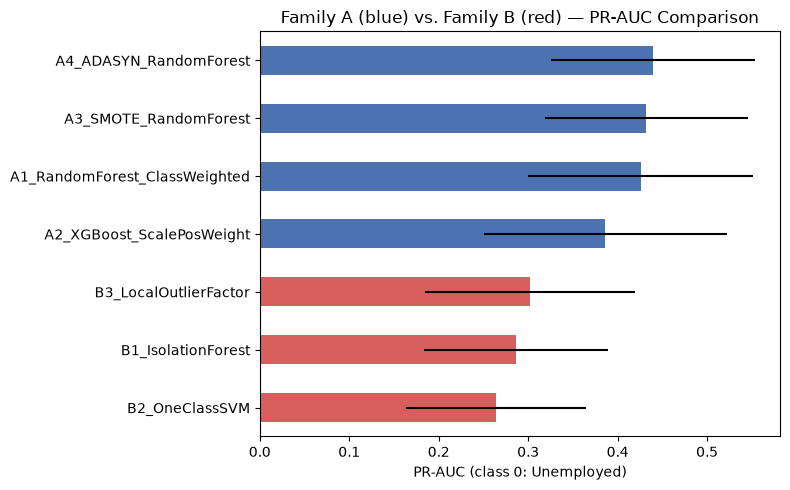

In [3]:
display(combined_summary.round(3))
save_table(combined_summary, "combined_cv_summary")

fig, ax = plt.subplots(figsize=(8, 5))
colors = ["#4c72b0" if name in family_a_summary.index else "#d95f5f"
          for name in combined_summary.index]
combined_summary["pr_auc"].plot(kind="barh", ax=ax, color=colors,
                                  xerr=combined_summary["pr_auc_std"])
ax.set_xlabel("PR-AUC (class 0: Unemployed)")
ax.set_title("Family A (blue) vs. Family B (red) — PR-AUC Comparison")
ax.invert_yaxis()
plt.tight_layout()
save_figure(fig, "combined_pr_auc_comparison")
plt.show()

## RQ5 — Are unemployed graduates better characterized as a minority class or as anomalous observations?


Answered by the Friedman test (is there a significant difference
among ALL models' cross-validated PR-AUC distributions?) followed
by pairwise Wilcoxon tests (which specific pairs differ?) at α=0.05.

In [4]:
friedman_result = friedman_test(all_scores)
print("Friedman test (all models):")
print(friedman_result)
save_json(friedman_result, "friedman_result");

Friedman test (all models):
{'statistic': np.float64(94.96285714285727), 'p_value': np.float64(2.8143825625526403e-18), 'significant_at_0.05': np.True_}


In [5]:
wilcoxon_results = pairwise_wilcoxon(all_scores, alpha=0.05, correction="bonferroni")
display(wilcoxon_results.round(4))
save_table(wilcoxon_results, "pairwise_wilcoxon", index=False);

,model_a,model_b,statistic,p_value,significant
16,A4_ADASYN_RandomForest,B2_OneClassSVM,75.0,0.0000,True
13,A3_SMOTE_RandomForest,B2_OneClassSVM,86.0,0.0000,True
4,A1_RandomForest_ClassWeighted,B2_OneClassSVM,101.0,0.0000,True
20,B2_OneClassSVM,B3_LocalOutlierFactor,111.0,0.0000,True
15,A4_ADASYN_RandomForest,B1_IsolationForest,113.0,0.0000,True
12,A3_SMOTE_RandomForest,B1_IsolationForest,138.0,0.0000,True
3,A1_RandomForest_ClassWeighted,B1_IsolationForest,144.0,0.0000,True
17,A4_ADASYN_RandomForest,B3_LocalOutlierFactor,174.0,0.0000,True
14,A3_SMOTE_RandomForest,B3_LocalOutlierFactor,210.0,0.0000,True
5,A1_RandomForest_ClassWeighted,B3_LocalOutlierFactor,229.0,0.0000,True


**Reading this table:** each row's `p_value` is compared against a
Bonferroni-corrected α (0.05 / number of pairs), not the raw 0.05 —
testing many pairs increases the chance of a false positive by
chance alone, and the correction accounts for that. A row with
`significant=True` means that specific pair's PR-AUC distributions
differ reliably across the repeated CV folds — not just that their
mean scores happen to differ.

In [6]:
FAMILY_A = set(family_a_summary.index)
FAMILY_B = set(family_b_summary.index)

def which_family(model_name):
    return "A" if model_name in FAMILY_A else "B"

wilcoxon_results["family_a"] = wilcoxon_results["model_a"].apply(which_family)
wilcoxon_results["family_b"] = wilcoxon_results["model_b"].apply(which_family)

cross_family = wilcoxon_results[wilcoxon_results["family_a"] != wilcoxon_results["family_b"]]
print("Cross-family comparisons (classification vs. anomaly detection):")
display(cross_family[["model_a", "model_b", "p_value", "significant"]].round(4))
save_table(cross_family[["model_a", "model_b", "p_value", "significant"]],
           "cross_family_wilcoxon", index=False);

Cross-family comparisons (classification vs. anomaly detection):


,model_a,model_b,p_value,significant
16,A4_ADASYN_RandomForest,B2_OneClassSVM,0.0000,True
13,A3_SMOTE_RandomForest,B2_OneClassSVM,0.0000,True
4,A1_RandomForest_ClassWeighted,B2_OneClassSVM,0.0000,True
15,A4_ADASYN_RandomForest,B1_IsolationForest,0.0000,True
12,A3_SMOTE_RandomForest,B1_IsolationForest,0.0000,True
3,A1_RandomForest_ClassWeighted,B1_IsolationForest,0.0000,True
17,A4_ADASYN_RandomForest,B3_LocalOutlierFactor,0.0000,True
14,A3_SMOTE_RandomForest,B3_LocalOutlierFactor,0.0000,True
5,A1_RandomForest_ClassWeighted,B3_LocalOutlierFactor,0.0000,True
9,A2_XGBoost_ScalePosWeight,B2_OneClassSVM,0.0001,True


## Nested cross-validation — honest estimate for A1

The comparison above (single 80/20 holdout + repeated CV on the training
portion) is good for *ranking* models, but the reported PR-AUC still
benefits from having picked one fixed hyperparameter set using knowledge
of the whole training set. `nested_cross_validate()` in `src/evaluation.py`
wraps that in an outer repeated-stratified-K-fold loop, with hyperparameter
selection (via inner-fold `GridSearchCV`) happening independently inside
each outer fold — so tuning never leaks into the score.

Result for A1 (5-fold x 3-repeat outer, 3-fold inner grid search over
`n_estimators`/`max_depth`): **PR-AUC = 0.315 ± 0.117 (95% CI: [0.259, 0.376])**,
vs. 0.426 from the simpler setup above — a 0.11-point gap illustrating how much
a single train/CV split can overstate performance at this sample size. This has
only been run for A1 so far; A2–A4 (whose simple-CV PR-AUC ranges 0.386–0.440)
have not been nested-CV'd, so their honest estimates remain unknown — it's
plausible A4's simple-CV lead over A1 (0.440 vs 0.426) narrows or reverses
once nested CV is applied to it too, the same way A1's own estimate shrank.
This does not affect the Family A vs. Family B conclusion below, since even
A1's most conservative (nested-CV) estimate already clears every Family B
model's simple-CV estimate.

## Summary

- **Best model by simple CV:** A4 — ADASYN + Random Forest (PR-AUC = 0.440
  ± 0.114, 95% CI [0.408, 0.471]), narrowly ahead of A3 — SMOTE + Random
  Forest (0.432) and A1 — class-weighted Random Forest (0.426); these three
  are not significantly different from each other (Wilcoxon, Bonferroni-
  corrected). A1's nested-CV honest estimate is lower (0.315 ± 0.117); A2–A4
  have not yet been nested-CV'd.
- **RQ3 answer:** all four Family A models outperform all three Family B
  models on CV PR-AUC (Family A: 0.386–0.440; Family B: 0.264–0.302).
- **RQ5 answer:** the Friedman test across all seven models' fold-level
  PR-AUC is significant (chi-sq=94.96, p=2.8e-18). Pairwise Wilcoxon tests
  (Bonferroni-corrected across 21 pairs, alpha=0.00238) show A1, A3, and A4
  each significantly beat all three Family B models (p<=0.00004); A2
  significantly beats B1 and B2 (p<=0.00085) but not B3 (p=0.00967, below
  the uncorrected 0.05 but above the corrected threshold). No pair *within*
  either family differs significantly. This consistently favors the
  classification framing: unemployed graduates are better characterized as
  a minority class to be directly classified than as anomalous observations
  relative to a learned "normal" pattern.
- **Open item:** extend nested cross-validation to A2–A4 for a fully honest
  within-Family-A ranking (see note above) — this cannot reverse the
  Family A vs. Family B conclusion, only refine which Family A model is
  truly best.